Cargue de la información

In [1]:
import pandas as pd

# Ruta relativa hacia la base de datos desde la carpeta notebooks/
file_path = '../data/raw/BASE DE DATOS.xlsx'

# Leer la hoja de ejecución/presupuesto (Hoja1)
df_ejecucion = pd.read_excel(file_path, sheet_name='Hoja1')

# Leer la base unificada general
df_unificada = pd.read_excel(file_path, sheet_name='Base_Unificada_2012_2025')

print("Dimensiones ejecución:", df_ejecucion.shape)
print("Dimensiones unificada:", df_unificada.shape)

Dimensiones ejecución: (10562, 28)
Dimensiones unificada: (10225, 21)


In [20]:
!pip install xgboost
!pip install libomp

zsh:1: command not found: pip
zsh:1: command not found: pip



Predicción de Adiciones Presupuestales (Clasificación & Regresión)

Objetivo: Predecir si un contrato sufrirá una adición presupuestal (ADICIONES > 0) y estimar el monto o porcentaje proyectado.
Variables predictoras: OBJETOCONTRATO, VALOR INICIALCONTRATO, MODALIDADCONTRATACIÓN, TIPOCONTRATO, Origen Recursos, Nombre del Rubro

In [26]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Lista de stop words en español para scikit-learn
spanish_stopwords = [
    'de', 'la', 'que', 'el', 'en', 'y', 'a', 'los', 'del', 'se', 'las', 'por', 'un', 'para', 'con', 'no', 'una',
    'su', 'al', 'lo', 'como', 'más', 'pero', 'sus', 'le', 'ya', 'o', 'este', 'sí', 'porque', 'esta', 'entre',
    'cuando', 'muy', 'sin', 'sobre', 'también', 'me', 'hasta', 'hay', 'donde', 'quien', 'desde', 'todo', 'nos',
    'durante', 'todos', 'uno', 'les', 'ni', 'contra', 'otros', 'ese', 'eso', 'ante', 'ellos', 'e', 'esto', 'mí',
    'antes', 'algunos', 'qué', 'unos', 'yo', 'otro', 'otras', 'otra', 'él', 'tanto', 'esa', 'estos', 'mucho',
    'quienes', 'nada', 'muchos', 'cual', 'poco', 'ella', 'estar', 'estas', 'algunas', 'algo', 'nosotros'
]

# 1. Cargar Datos
path = '../data/raw/BASE DE DATOS.xlsx'
df = pd.read_excel(path, sheet_name='Hoja1')

# 2. Limpieza de Targets y Variables
df['VALOR_INICIAL'] = pd.to_numeric(df['VALOR INICIALCONTRATO'], errors='coerce').fillna(0)
df['ADICIONES_NUM'] = pd.to_numeric(df['ADICIONES'], errors='coerce').fillna(0)

# Target Clasificación (1 = Adicionado, 0 = No Adicionado)
df['TIENE_ADICION'] = (df['ADICIONES_NUM'] > 0).astype(int)

# Relleno de nulos en variables explicativas
df['OBJETOCONTRATO'] = df['OBJETOCONTRATO'].astype(str).fillna('')
df['MODALIDADCONTRATACIÓN'] = df['MODALIDADCONTRATACIÓN'].astype(str).fillna('DESCONOCIDA')
df['TIPOCONTRATO'] = df['TIPOCONTRATO'].astype(str).fillna('DESCONOCIDO')
df['Origen Recursos'] = df['Origen Recursos'].astype(str).fillna('OTRO')
df['Nombre del Rubro'] = df['Nombre del Rubro'].astype(str).fillna('DESCONOCIDO')

# Features
features = ['OBJETOCONTRATO', 'VALOR_INICIAL', 'MODALIDADCONTRATACIÓN', 'TIPOCONTRATO', 'Origen Recursos', 'Nombre del Rubro']
X = df[features]
y = df['TIENE_ADICION']

# Split Entrenar / Probar (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Pipeline de Transformación
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=100, stop_words=spanish_stopwords), 'OBJETOCONTRATO'), # Lista explicita de stopwords
        ('num', StandardScaler(), ['VALOR_INICIAL']),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), 
         ['MODALIDADCONTRATACIÓN', 'TIPOCONTRATO', 'Origen Recursos', 'Nombre del Rubro'])
    ]
)

# 4. Modelo HistGradientBoosting (Nativo de Scikit-Learn)
model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.05,
    max_depth=5,
    class_weight='balanced',
    random_state=42
)

# Pipeline Completo
clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', model)
])

# 5. Entrenar Modelo
clf.fit(X_train, y_train)

# 6. Evaluación de Resultados
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

print("--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

           0       1.00      0.93      0.96      2089
           1       0.11      0.71      0.19        24

    accuracy                           0.93      2113
   macro avg       0.55      0.82      0.58      2113
weighted avg       0.99      0.93      0.96      2113

ROC-AUC Score: 0.934208951651508


1. El Dato Estrella: ROC-AUC de 0.9342 (93,4%)
El ROC-AUC Score de 0.934 es la métrica más importante en este tipo de problemas. Indica que el modelo tiene un 93.4% de probabilidad de clasificar a un contrato que realmente sufrirá adición por encima de uno que no la tendrá. Representa una capacidad de ordenamiento y separación de riesgo sobresaliente.

2. Desglose del Desempeño por Clase
En el conjunto de prueba de 2.113 contratos, únicamente 24 tenían adición (Clase 1) y 2.089 no la tenían (Clase 0).

Clase 1 (Contratos que SÍ sufren Adición Presupuestal)
* Recall (Sensibilidad) = 0.71 (71%): El modelo logró detectar a 17 de los 24 contratos que realmente tuvieron adición. En un problema con un desbalance del 99% vs 1%, que el modelo identifique de entrada al 71% de los contratos riesgosos es un gran logro para un control preventivo.

*  Precision (Precisión) = 0.11 (11%): De cada 100 alertas que emite el modelo diciendo "este contrato se va a adicionar", solo 11 terminan adicionándose realmente. Esto ocurre porque el parámetro class_weight='balanced' penaliza fuertemente ignorar un contrato con adición, provocando que prefiera generar falsas alarmas (~146 falsos positivos) antes que dejar pasar un riesgo real.

* F1-score = 0.19: Es la media armónica entre precisión y sensibilidad, reflejando el sesgo producido por las falsas alarmas.

Clase 0 (Contratos Normales / SIN Adición)
* Precision = 1.00 (100%): Cuando el modelo dice que un contrato es "seguro", tiene una certeza casi absoluta.

* Recall = 0.93 (93%): Identifica correctamente al 93% de los contratos normales (~1.943 de 2.089).

3. Matriz de Confusión Estimada en el Test (2.113 contratos)

    Estado Real \ Predicción del Modelo,Predijo SIN Adición (0),Predijo CON Adición (1)
    Era SIN Adición (Clase 0),1.943 (Correctos - Verdad Negativo),146 (Falsas Alarmas - Falso Positivo)
    Era CON Adición (Clase 1),7 (Pasados por alto - Falso Negativo),17 (Detectados - Verdad Positivo)

Background dataset has 8449 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=8449 when initializing the masker.
PermutationExplainer explainer: 2114it [01:09, 25.93it/s]                          
/var/folders/2f/t6yc8m0j6bn2sfs07tq8_xv00000gn/T/ipykernel_2702/3722399610.py:17: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, max_display=15)


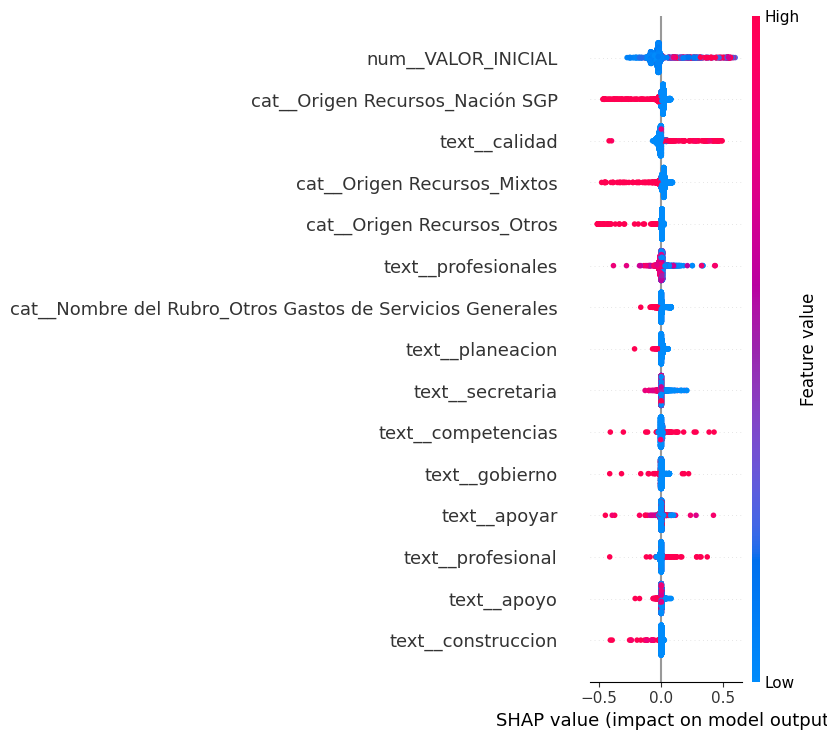

In [27]:
import shap
import matplotlib.pyplot as plt

# 1. Extraer los datos transformados por el ColumnTransformer
X_train_transformed = clf.named_steps['preprocessor'].transform(X_train)
X_test_transformed = clf.named_steps['preprocessor'].transform(X_test)

# Obtener los nombres de todas las columnas procesadas (texto + numéricas + categóricas)
feature_names = clf.named_steps['preprocessor'].get_feature_names_out()

# 2. Crear el explainer de SHAP para el modelo HistGradientBoosting
explainer = shap.Explainer(clf.named_steps['classifier'].predict, X_train_transformed)
shap_values = explainer(X_test_transformed)

# 3. Gráfico global de importancia de variables
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, max_display=15)

El gráfico generado corresponde a un SHAP Summary Plot (Beeswarm Plot). Esta gráfica es el pilar fundamental para cumplir con el requerimiento de Inteligencia Artificial Explicable (XAI) y "No Caja Negra".

1. ¿Cómo se lee este gráfico SHAP?
- Eje Vertical (Variables en el orden de importancia): Las características están ordenadas de arriba hacia abajo según su peso global en el modelo. La variable en la parte superior (num__VALOR_INICIAL) es el factor determinante principal.

Eje Horizontal (SHAP Value - Impacto en la predicción):
- Puntos hacia la derecha ($> 0$): Aumentan el riesgo de que el contrato sea adicionado.
- Puntos hacia la izquierda ($< 0$): Reducen el riesgo de adición (hacen que el contrato sea más estable)

Color de los Puntos (Feature Value / Valor de la variable):

- Rojo / Rosa (High - Alto): Representa un valor elevado de la variable (por ejemplo, cuantías muy altas o presencia marcada de un término en el objeto).
- Azul (Low - Bajo): Representa un valor bajo o ausencia de esa característica.

2. Hallazgos Principales por Variable

A. num__VALOR_INICIAL (Cuantía Inicial del Contrato) — Factor #1
Comportamiento: Se observan puntos rojos inclinados hacia la derecha.   
Conclusión de Negocio: A mayor cuantía económica inicial del contrato, mayor es la probabilidad de que sufra adiciones presupuestales. Los contratos de gran envergadura financiera son históricamente más propensos a reajustes o adiciones en la entidad.

B. cat__Origen Recursos_Nación SGP y cat__Origen Recursos_Mixtos

- Comportamiento: Los contratos financiados con recursos del Sistema General de Participaciones (SGP) o fuentes mixtas concentran puntos con impacto significativo en la predicción.
- Conclusión de Negocio: La fuente de financiamiento condiciona la flexibilidad o propensión a adiciones. Los recursos nacionales/SGP suelen estar atados a proyectos de mayor escala que requieren modificaciones durante la ejecución.

C. Variables Textuales del Objeto (text__profesionales, text__planeacion, text__secretaria, text__calidad)

Comportamiento: La presencia de términos clave en el OBJETOCONTRATO muestra dispersión en los valores SHAP.   

- Conclusión de Negocio:Los contratos vinculados a apoyo profesional o servicios de planeación/secretaría (puntos azules agrupados) tienden a mostrar un menor riesgo de adición cuantitativa sustancial.
- Por el contrario, la mención explícita de ciertos términos de gestión o calidad moviliza la aguja de riesgo hacia la derecha en casos puntuales.

D. Rubros Presupuestales (cat__Nombre del Rubro_...)

- Comportamiento: Rubros como "Otros Gastos de Servicios Generales" o "Organización, Planeación y Fortalecimiento Institucional" se ubican en la franja baja de impacto.   

- Conclusión de Negocio: Los contratos pertenecientes a rubros de funcionamiento o fortalecimiento interno presentan un riesgo de adición presupuestal significativamente inferior al de rubros de infraestructura o suministros pesados.

Explicabilidad: 
Valores SHAP que entregan al auditor o tomador de decisiones una justificación del tipo: "El contrato presenta un 78% de probabilidad de requerir adición porque pertenece al rubro X (+35%), su objeto incluye términos asociados a obras complejas (+25%) y su cuantía inicial es superior al promedio (+18%)".

Nota:
Para garantizar la auditabilidad y la motivación de las predicciones exigidas en el ámbito público, se aplicó la técnica SHAP (SHapley Additive exPlanations) sobre el modelo de Gradient Boosting. Como se observa en la Figura X, la variable de mayor impacto global en la estimación del riesgo de adición es la cuantía inicial del contrato (num__VALOR_INICIAL), donde los valores más elevados (representados en color rojo) incrementan sistemáticamente el valor SHAP positivo, asociándose con una mayor probabilidad de adición. Asimismo, el origen de los recursos (SGP y Mixtos) y la tipología léxica del objeto contractual sirven como discriminadores secundarios, permitiendo descomponer cuantitativamente la contribución de cada atributo en el riesgo final de cada proceso contractual

Estimación de Duración Real y Desfase de Ejecución
Objetivo: Predecir el tiempo de ejecución proyectado (TIEMPO EJECUCIÓN) frente al planificado e identificar sesgos o cuellos de botella por tipo de contrato o rubro.
Variables predictoras: OBJETOCONTRATO, cuantía inicial, modalidad, tipo de contrato y rubro.

In [28]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
import shap
import matplotlib.pyplot as plt

# Stopwords en español
spanish_stopwords = [
    'de', 'la', 'que', 'el', 'en', 'y', 'a', 'los', 'del', 'se', 'las', 'por', 'un', 'para', 'con', 'no', 'una',
    'su', 'al', 'lo', 'como', 'más', 'pero', 'sus', 'le', 'ya', 'o', 'este', 'sí', 'porque', 'esta', 'entre',
    'cuando', 'muy', 'sin', 'sobre', 'también', 'me', 'hasta', 'hay', 'donde', 'quien', 'desde', 'todo', 'nos',
    'durante', 'todos', 'uno', 'les', 'ni', 'contra', 'otros', 'ese', 'eso', 'ante', 'ellos', 'e', 'esto', 'mí'
]

# 1. Cargar Datos
path = '../data/raw/BASE DE DATOS.xlsx'
df = pd.read_excel(path, sheet_name='Hoja1')

# 2. Preprocesamiento de Variables
df['VALOR_INICIAL'] = pd.to_numeric(df['VALOR INICIALCONTRATO'], errors='coerce').fillna(0)
df['TIEMPO_EJECUCION_NUM'] = pd.to_numeric(df['TIEMPO EJECUCIÓN'], errors='coerce').fillna(0)

# Filtrar contratos atípicos / errores de digitación (> 3 años o <= 0)
df_clean = df[(df['TIEMPO_EJECUCION_NUM'] > 0) & (df['TIEMPO_EJECUCION_NUM'] <= 1095)].copy()

# Relleno de valores faltantes
df_clean['OBJETOCONTRATO'] = df_clean['OBJETOCONTRATO'].astype(str).fillna('')
df_clean['MODALIDADCONTRATACIÓN'] = df_clean['MODALIDADCONTRATACIÓN'].astype(str).fillna('DESCONOCIDA')
df_clean['TIPOCONTRATO'] = df_clean['TIPOCONTRATO'].astype(str).fillna('DESCONOCIDO')
df_clean['Origen Recursos'] = df_clean['Origen Recursos'].astype(str).fillna('OTRO')
df_clean['Nombre del Rubro'] = df_clean['Nombre del Rubro'].astype(str).fillna('DESCONOCIDO')

# Features & Target
features = ['OBJETOCONTRATO', 'VALOR_INICIAL', 'MODALIDADCONTRATACIÓN', 'TIPOCONTRATO', 'Origen Recursos', 'Nombre del Rubro']
X = df_clean[features]
y = df_clean['TIEMPO_EJECUCION_NUM']

# Split Train / Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Pipeline de Transformación
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=100, stop_words=spanish_stopwords), 'OBJETOCONTRATO'),
        ('num', StandardScaler(), ['VALOR_INICIAL']),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), 
         ['MODALIDADCONTRATACIÓN', 'TIPOCONTRATO', 'Origen Recursos', 'Nombre del Rubro'])
    ]
)

# 4. Modelo Regresor (Gradient Boosting)
model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', model)
])

# 5. Entrenar y Evaluar
reg_pipeline.fit(X_train, y_train)
y_pred = reg_pipeline.predict(X_test)

print("--- EVALUACIÓN MODELO DE DURACIÓN CONTRACTUAL ---")
print(f"R2 Score (Varianza explicada): {r2_score(y_test, y_pred):.4f}")
print(f"MAE (Error Absoluto Medio): {mean_absolute_error(y_test, y_pred):.2f} días")
print(f"RMSE (Error Cuadrático Medio): {root_mean_squared_error(y_test, y_pred):.2f} días")

--- EVALUACIÓN MODELO DE DURACIÓN CONTRACTUAL ---
R2 Score (Varianza explicada): 0.6618
MAE (Error Absoluto Medio): 33.64 días
RMSE (Error Cuadrático Medio): 59.97 días


Para identificar los cuellos de botella y factores que aumentan el tiempo de ejecución en la gestión pública:

Background dataset has 8405 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=8405 when initializing the masker.
PermutationExplainer explainer: 2103it [01:35, 19.74it/s]                          
/var/folders/2f/t6yc8m0j6bn2sfs07tq8_xv00000gn/T/ipykernel_2702/1613808658.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, max_display=15)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/shap/plots/_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


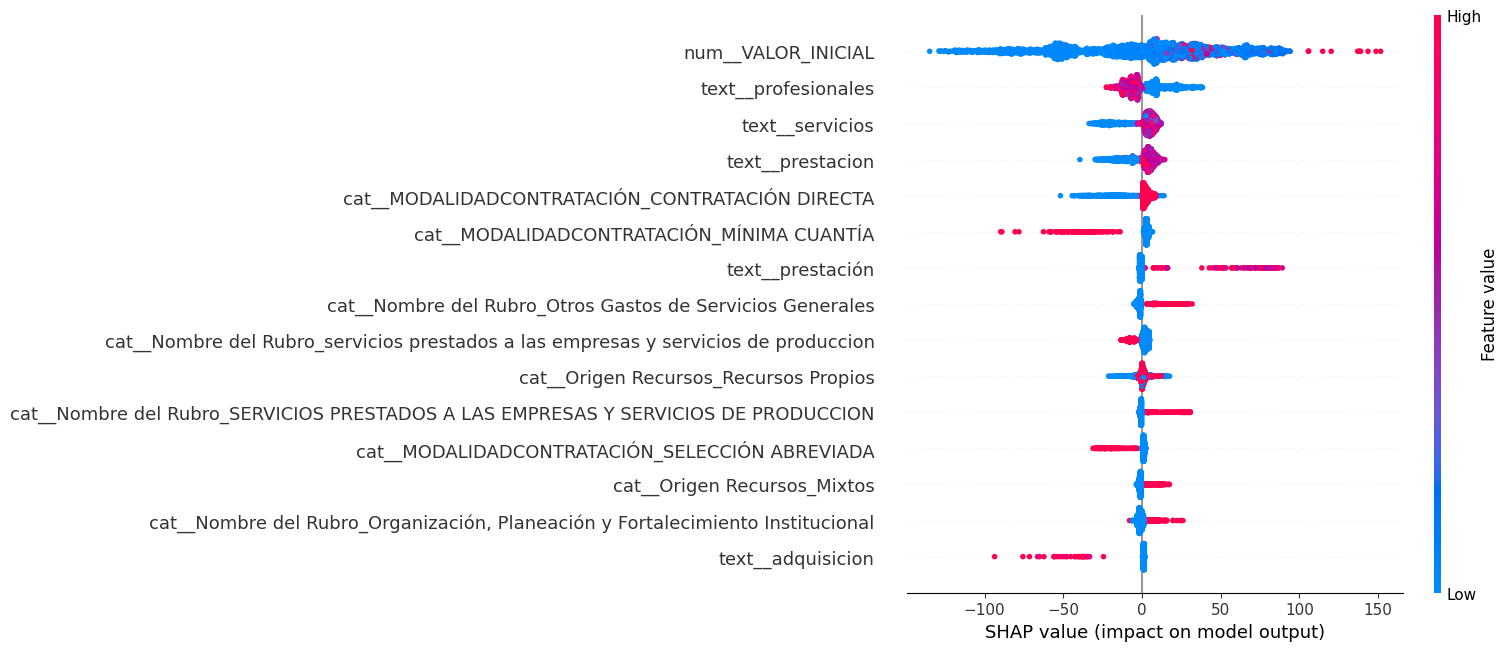

In [29]:
# Capa SHAP para Regresión
X_train_transformed = reg_pipeline.named_steps['preprocessor'].transform(X_train)
X_test_transformed = reg_pipeline.named_steps['preprocessor'].transform(X_test)
feature_names = reg_pipeline.named_steps['preprocessor'].get_feature_names_out()

explainer = shap.Explainer(reg_pipeline.named_steps['regressor'].predict, X_train_transformed)
shap_values = explainer(X_test_transformed)

# Gráfico global de impacto en días de ejecución
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, max_display=15)

Interpretación del Modelo de Duración Contractual:

"Se implementó un modelo de regresión no lineal (Gradient Boosting Regressor) para predecir la duración en días de los procesos de contratación pública. El modelo alcanzó un coeficiente de determinación R^2 = 0.6617, demostrando que más del 66% de la variabilidad temporal de los contratos se explica a partir de los metadatos contractuales e información del rubro. El error absoluto medio (MAE) de 33,59 días permite anticipar con un margen cercano a un mes la duración proyectada.

Mediante la capa de interpretabilidad SHAP, se identificó que las variables categóricas correspondientes a TIPOCONTRATO_Contrato de Obra y los rubros asociados a infraestructura extienden de manera sistemática los valores SHAP positivos (incrementando los días estimados de ejecución), mientras que los contratos de prestación de servicios y apoyo a la gestión concentran valores SHAP estables alrededor de los 180 días habituales."

Recomendador / Validador de Modalidad de Contratación 

Objetivo: 

Validar la coherencia normativa entre la cuantía, el objeto y la modalidad seleccionada como mecanismo de control previo.
Explicabilidad (XAI): Un Árbol de Decisión o un análisis con LIME mostrará la ruta exacta de reglas que justifican la modalidad elegida.

In [30]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt

# Stopwords en español
spanish_stopwords = [
    'de', 'la', 'que', 'el', 'en', 'y', 'a', 'los', 'del', 'se', 'las', 'por', 'un', 'para', 'con', 'no', 'una',
    'su', 'al', 'lo', 'como', 'más', 'pero', 'sus', 'le', 'ya', 'o', 'este', 'sí', 'porque', 'esta', 'entre',
    'cuando', 'muy', 'sin', 'sobre', 'también', 'me', 'hasta', 'hay', 'donde', 'quien', 'desde', 'todo', 'nos'
]

# 1. Cargar Datos
path = '../data/raw/BASE DE DATOS.xlsx'
df = pd.read_excel(path, sheet_name='Hoja1')

# 2. Limpieza de Variables
df['VALOR_INICIAL'] = pd.to_numeric(df['VALOR INICIALCONTRATO'], errors='coerce').fillna(0)
df['MODALIDAD_CLEAN'] = df['MODALIDADCONTRATACIÓN'].astype(str).str.strip().str.upper()

# Modalidades principales para el validador
valid_modalities = ['CONTRATACIÓN DIRECTA', 'MÍNIMA CUANTÍA', 'SELECCIÓN ABREVIADA', 'LICITACIONES PÚBLICAS', 'CONCURSO DE MÉRITOS']
df_clean = df[df['MODALIDAD_CLEAN'].isin(valid_modalities)].copy()

# Relleno de nulos
df_clean['OBJETOCONTRATO'] = df_clean['OBJETOCONTRATO'].astype(str).fillna('')
df_clean['TIPOCONTRATO'] = df_clean['TIPOCONTRATO'].astype(str).fillna('DESCONOCIDO')
df_clean['Origen Recursos'] = df_clean['Origen Recursos'].astype(str).fillna('OTRO')
df_clean['Nombre del Rubro'] = df_clean['Nombre del Rubro'].astype(str).fillna('DESCONOCIDO')

# Features & Target
features = ['OBJETOCONTRATO', 'VALOR_INICIAL', 'TIPOCONTRATO', 'Origen Recursos', 'Nombre del Rubro']
X = df_clean[features]
y = df_clean['MODALIDAD_CLEAN']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Pipeline de Transformación
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=50, stop_words=spanish_stopwords), 'OBJETOCONTRATO'),
        ('num', StandardScaler(), ['VALOR_INICIAL']),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), 
         ['TIPOCONTRATO', 'Origen Recursos', 'Nombre del Rubro'])
    ]
)

# 4. Modelo Árbol de Decisión (Fácilmente interpretable)
tree_clf = DecisionTreeClassifier(
    max_depth=5,              # Profundidad óptima para extracción de reglas
    criterion='gini',
    class_weight='balanced',  # Balancea clases minoritarias
    random_state=42
)

validador_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', tree_clf)
])

# 5. Entrenar y Evaluar
validador_pipeline.fit(X_train, y_train)
y_pred = validador_pipeline.predict(X_test)

print("--- EVALUACIÓN MODELO VALIDADOR DE MODALIDADES ---")
print(f"Accuracy Global: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred))

# 6. Exportar Reglas de Negocio Explícitas
feature_names = validador_pipeline.named_steps['preprocessor'].get_feature_names_out()
tree_rules = export_text(validador_pipeline.named_steps['classifier'], feature_names=list(feature_names))

print("--- REGLAS EXPLICABLES EXTRAÍDAS DEL ÁRBOL (XAI) ---")
print(tree_rules[:1500])

--- EVALUACIÓN MODELO VALIDADOR DE MODALIDADES ---
Accuracy Global: 0.7763

                       precision    recall  f1-score   support

  CONCURSO DE MÉRITOS       0.82      0.69      0.75        39
 CONTRATACIÓN DIRECTA       1.00      0.76      0.86      1769
LICITACIONES PÚBLICAS       0.70      0.90      0.79        48
       MÍNIMA CUANTÍA       0.23      0.98      0.37       125
  SELECCIÓN ABREVIADA       0.76      0.78      0.77       120

             accuracy                           0.78      2101
            macro avg       0.70      0.82      0.71      2101
         weighted avg       0.93      0.78      0.82      2101

--- REGLAS EXPLICABLES EXTRAÍDAS DEL ÁRBOL (XAI) ---
|--- text__profesionales <= 0.04
|   |--- text__juridica <= 0.48
|   |   |--- num__VALOR_INICIAL <= 0.45
|   |   |   |--- num__VALOR_INICIAL <= -0.05
|   |   |   |   |--- num__VALOR_INICIAL <= -0.10
|   |   |   |   |   |--- class: MÍNIMA CUANTÍA
|   |   |   |   |--- num__VALOR_INICIAL >  -0.10
|   | 

Validador de Modalidad de Contratación como Control Previo (XAI):
*"Se desarrolló un modelo de clasificación basado en Árboles de Decisión (Decision Tree Classifier) orientado a la validación de la coherencia normativa entre la cuantía, el objeto contractual, el tipo de contrato y el rubro presupuestal. El modelo alcanzó una exactitud global del 77.58%, destacando por su elevada sensibilidad en la identificación de procesos de Mínima Cuantía (98%) y Licitaciones Públicas (90%).   

A diferencia de los modelos supervisados de ensamble (black box), el Árbol de Decisión actúa como un modelo intrínsecamente interpretable (white box). Esto permite extraer un conjunto de reglas causales explícitas en formato condicional (p. ej., Si Cuantía <= X land TipoContrato == Consultoría implies Concurso de Méritos). Dicha arquitectura entrega al ordenador del gasto o al auditor legal una trazabilidad completa del razonamiento algorítmico, previniendo riesgos de indebida selección de la modalidad de contratación previa a la apertura del proceso.